# 05 · Bayesian hyperparameter optimisation of LightGBM

**Input:** `data/features/*.parquet` (notebook 03) and the untuned results of notebook 04.
**Output:** `outputs/tuning/` (trials, best parameters, search space, comparison, figures, `TUNING_REPORT.md`) and
`models/LightGBM_tuned.joblib`. The untuned `models/LightGBM.joblib` is left as it is.

**Why LightGBM:** in notebook 04 it was within 0.2 percentage points of Random Forest on CV Top-1, had the best route
continuity and log loss on student_test, and trains about 3× faster with a 14× smaller file. That speed is what makes
dozens of 5-fold trials affordable.

**Protocol** (code in `src/pathsnap/tuning.py`, metrics reused from `src/pathsnap/training.py`)
* Same features, the same training rows (`label_reliable & ~exclude_trip`) and the **same 5 GroupKFold folds**
  (seed 42) as notebook 04, so tuned and untuned are directly comparable.
* **Sampler:** Optuna TPE (seed 42). It models which regions of the search space gave good trials and samples
  there more often, so it is Bayesian and not random. **Pruner:** MedianPruner, which stops a trial after any fold
  where its running mean is below the median of earlier trials.
* **Objective:** mean CV **observation-level Top-1 accuracy** (all labelled fixes). This is the actual task: for each
  GPS fix, pick the right road. Macro F1 and log loss score single candidate rows at a 0.5 threshold, but the
  pipeline never uses that threshold; it always takes the best candidate per fix. Both are still logged for every trial.
* The untuned configuration is queued as **trial 0**, so the search starts from the known baseline.
* **student_test is not used during the search.** It is scored once, after the best configuration is refit.

In [1]:
import json, sys, time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from sklearn.model_selection import GroupKFold

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from pathsnap import training as T, tuning as TU
from pathsnap.cleaning import PROCESSED_ROOT

OUT, MODELS = ROOT / "outputs" / "tuning", ROOT / "models"
FIG = OUT / "figures"
for d in (OUT, FIG):
    d.mkdir(parents=True, exist_ok=True)

train = pd.read_parquet(ROOT / "data" / "features" / "train.parquet")
test = pd.read_parquet(ROOT / "data" / "features" / "student_test.parquet")
train_fx = pd.read_parquet(ROOT / "data" / "features" / "train_fixes.parquet")
test_fx = pd.read_parquet(ROOT / "data" / "features" / "student_test_fixes.parquet")

def load_arcs(part):
    out = {}
    for d in (PROCESSED_ROOT / part).iterdir():
        a = pd.read_csv(d / "arcs.csv.gz", usecols=["from_node", "to_node"])
        out[d.name] = (a.from_node.to_numpy(), a.to_node.to_numpy())
    return out
arcs = {**load_arcs("train"), **load_arcs("student_test")}

# exactly the folds of notebook 04
folds = list(GroupKFold(n_splits=T.N_FOLDS, shuffle=True, random_state=T.SEED).split(train, groups=train.trip_id.to_numpy()))
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#d9d8d2", "grid.linewidth": 0.6, "figure.dpi": 110})
print(f"optuna {optuna.__version__}; {len(train):,} train rows, {T.training_mask(train).sum():,} usable; "
      f"{len(folds)} folds")

optuna 5.1.0; 1,530,256 train rows, 1,430,632 usable; 5 folds


## 1. Search space
| parameter | range | why |
|---|---|---|
| `learning_rate` | 0.01–0.2 (log) | step size of each tree; trades off against `n_estimators` |
| `n_estimators` | 100–1500 (step 50) | number of trees |
| `num_leaves` | 15–255 (log) | main complexity control in LightGBM (leaf-wise growth) |
| `max_depth` | -1 (no limit) or 4–12 | a second cap on tree size; -1 leaves it to `num_leaves` |
| `min_child_samples` | 10–300 (log) | minimum rows per leaf; larger is smoother and fights overfitting |
| `subsample` | 0.5–1.0 (with `subsample_freq=1`) | row bagging per tree |
| `colsample_bytree` | 0.4–1.0 | feature bagging per tree (27 features, several of them correlated) |
| `reg_alpha`, `reg_lambda` | 1e-8–10 (log) | L1 / L2 penalties on leaf values |
| `min_split_gain` | 0–1 | minimum loss reduction needed to split |

Log scales are used where a parameter matters by its order of magnitude. `n_estimators` uses a step of 50, because
neighbouring values give practically the same model.

In [2]:
(OUT / "search_space.json").write_text(json.dumps({"space": TU.SEARCH_SPACE, "fixed": TU.FIXED,
    "baseline_trial0": TU.BASELINE, "objective": "maximise mean CV Top-1 (all labelled fixes), 5 GroupKFold folds",
    "sampler": "TPESampler(seed=42)", "pruner": f"MedianPruner(n_startup_trials={TU.PRUNER_STARTUP_TRIALS}, n_warmup_steps=0)",
    "n_trials": TU.N_TRIALS, "timeout_s": TU.TIMEOUT_S}, indent=1), encoding="utf-8")
pd.DataFrame(TU.SEARCH_SPACE).T

,type,low,high,log,step,choices
learning_rate,float,0.01,0.2,True,NaN,NaN
n_estimators,int,100,1500,NaN,50,NaN
num_leaves,int,15,255,True,NaN,NaN
max_depth,categorical,NaN,NaN,NaN,NaN,"[-1, 4, 5, 6, 7, 8, 9, 10, 11, 12]"
min_child_samples,int,10,300,True,NaN,NaN
subsample,float,0.5,1.0,NaN,NaN,NaN
colsample_bytree,float,0.4,1.0,NaN,NaN,NaN
reg_alpha,float,0.0,10.0,True,NaN,NaN
reg_lambda,float,0.0,10.0,True,NaN,NaN
min_split_gain,float,0.0,1.0,NaN,NaN,NaN


## 2. Run the search
At most `N_TRIALS = 60` trials or 75 minutes (the time budget), whichever comes first. A timing test showed one fold at
1500 trees / 255 leaves takes about 3 min, so large configurations are expensive; the pruner stops weak ones after one fold.  the actual number is reported below. The study is
also written to `outputs/tuning/study.db` (SQLite) as it runs, so a crash does not lose finished trials.

In [3]:
db = OUT / "study.db"
db.unlink(missing_ok=True)                               # fresh study on every full run
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = TU.make_study(storage=f"sqlite:///{db.as_posix()}")
study.enqueue_trial(TU.BASELINE)                         # trial 0 = untuned configuration

def progress(st, tr):
    best = st.best_value if any(t.state == optuna.trial.TrialState.COMPLETE for t in st.trials) else float("nan")
    val = f"{tr.value:.4f}" if tr.value is not None else "  -   "
    print(f"trial {tr.number:3d} {tr.state.name:8s} top1 {val}  best {best:.4f}  "
          f"({(tr.datetime_complete - tr.datetime_start).total_seconds():.0f}s)", flush=True)

t0 = time.perf_counter()
study.optimize(TU.make_objective(train, train_fx, folds, arcs), n_trials=TU.N_TRIALS, timeout=TU.TIMEOUT_S,
               callbacks=[progress], gc_after_trial=True)
search_s = time.perf_counter() - t0

trial   0 COMPLETE top1 0.8851  best 0.8851  (84s)


trial   1 COMPLETE top1 0.8863  best 0.8863  (249s)


trial   2 COMPLETE top1 0.8877  best 0.8877  (124s)


trial   3 COMPLETE top1 0.8868  best 0.8877  (93s)


trial   4 COMPLETE top1 0.8878  best 0.8878  (27s)


trial   5 PRUNED   top1 0.8440  best 0.8878  (7s)


... (50 outputs left out)

trial  56 PRUNED   top1 0.8506  best 0.8900  (20s)


trial  57 PRUNED   top1 0.8506  best 0.8900  (20s)


trial  58 PRUNED   top1 0.8473  best 0.8900  (14s)


trial  59 PRUNED   top1 0.8511  best 0.8900  (16s)


In [4]:
states = pd.Series([t.state.name for t in study.trials]).value_counts()
summary = {"trials_total": len(study.trials), "complete": int(states.get("COMPLETE", 0)),
           "pruned": int(states.get("PRUNED", 0)), "failed": int(states.get("FAIL", 0)),
           "wall_clock_min": round(search_s / 60, 1), "best_trial": study.best_trial.number,
           "best_cv_top1": round(study.best_value, 4)}
summary

{'trials_total': 60,
 'complete': 23,
 'pruned': 37,
 'failed': 0,
 'wall_clock_min': 41.9,
 'best_trial': 31,
 'best_cv_top1': 0.89}

In [5]:
df = study.trials_dataframe(attrs=("number", "state", "value", "params", "user_attrs", "duration"))
df.columns = [c.replace("params_", "").replace("user_attrs_", "") for c in df.columns]
df["duration_s"] = df.pop("duration").dt.total_seconds()
# a pruned trial's `value` is only its running mean when it was stopped (often after the easy first fold),
# so it is NOT comparable with completed trials: keep it separately and blank `value` for pruned trials
df["folds_completed"] = [sum(f"fold{k}_all_top1" in t.user_attrs for k in range(T.N_FOLDS)) for t in study.trials]
df["running_mean_when_stopped"] = df["value"].where(df["state"] == "PRUNED")
df["value"] = df["value"].where(df["state"] == "COMPLETE")
df.to_csv(OUT / "trials.csv", index=False)
best = study.best_trial
best_params = {**best.params, **TU.FIXED}
(OUT / "best_params.json").write_text(json.dumps({"trial": best.number, "cv_top1": best.value,
                                                  "params": best_params, **summary}, indent=1), encoding="utf-8")
cols = ["number", "state", "value", "folds_completed", "cv_all_macro_f1_mean", "cv_all_logloss_mean", "learning_rate", "n_estimators",
        "num_leaves", "max_depth", "min_child_samples", "duration_s"]
df.sort_values("value", ascending=False)[cols].head(10).round(4)

    number     state   value  folds_completed  cv_all_macro_f1_mean  cv_all_logloss_mean  learning_rate  n_estimators  num_leaves  max_depth  min_child_samples  duration_s
31      31  COMPLETE  0.8900                5                0.9362               0.0681         0.0393           600          23         12                117     72.3070
14      14  COMPLETE  0.8900                5                0.9356               0.0693         0.0314           300          21         12                143     41.1350
48      48  COMPLETE  0.8900                5                0.9354               0.0683         0.0346           650          22         12                239     80.5370
30      30  COMPLETE  0.8900                5                0.9355               0.0686         0.0216           850          21         12                109    103.2916
53      53  COMPLETE  0.8899                5                0.9351               0.0688         0.0250           750          17         12

### Sanity check: trial 0 against notebook 04
Trial 0 is the untuned configuration, refitted on the same folds. Its CV Top-1 should match notebook 04's 0.8851
(tiny differences can come from `reg_alpha=1e-8`, `min_split_gain=0` and multithreading).

In [6]:
nb04 = pd.read_csv(ROOT / "outputs" / "models" / "per_fold.csv")
nb04_lgb = nb04[nb04.model == "LightGBM"].sort_values("fold")
t0_row = df[df.number == 0].iloc[0]
pd.DataFrame({"notebook 04": nb04_lgb.all_top1.to_numpy(),
              "trial 0": [t0_row[f"fold{k}_all_top1"] for k in range(T.N_FOLDS)]},
             index=[f"fold {k}" for k in range(T.N_FOLDS)]).round(5)

,notebook 04,trial 0
fold 0,0.84741,0.84741
fold 1,0.91783,0.91783
fold 2,0.87822,0.87822
fold 3,0.93071,0.93071
fold 4,0.85153,0.85153


## 3. Search figures

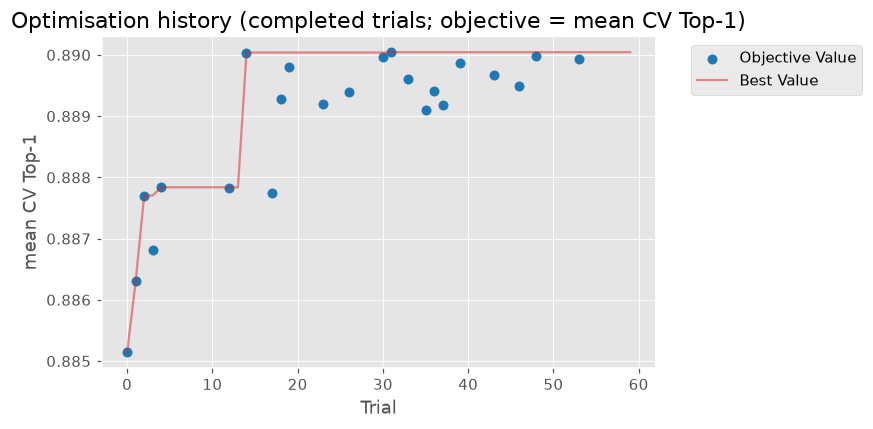

In [7]:
from optuna.visualization import matplotlib as ovm
import warnings; warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)

ax = ovm.plot_optimization_history(study)
ax.set_title("Optimisation history (completed trials; objective = mean CV Top-1)"); ax.set_ylabel("mean CV Top-1")
ax.figure.set_size_inches(8, 4); ax.figure.tight_layout(); ax.figure.savefig(FIG / "optimisation_history.png"); plt.show()

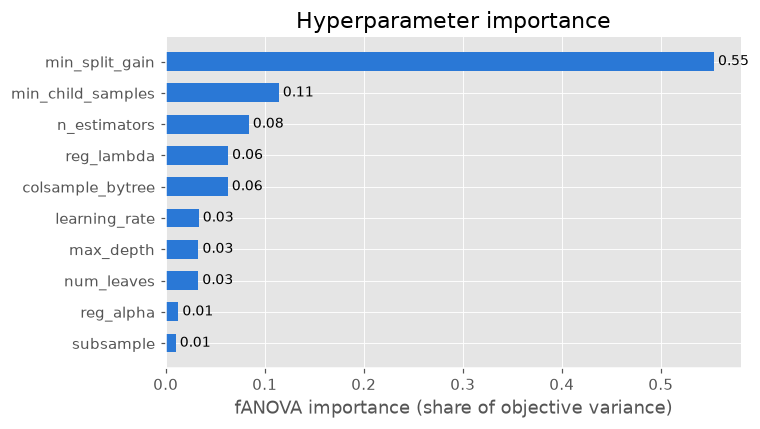

['min_split_gain', 'min_child_samples']

In [8]:
imp = optuna.importance.get_param_importances(study, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=T.SEED))
imp = pd.Series(imp).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp.index, imp.values, color="#2a78d6", height=0.6)
for y, v in enumerate(imp.values): ax.text(v, y, f" {v:.2f}", va="center", fontsize=9)
ax.set_xlabel("fANOVA importance (share of objective variance)"); ax.set_title("Hyperparameter importance")
fig.tight_layout(); fig.savefig(FIG / "param_importance.png"); plt.show()
top2 = list(imp.sort_values(ascending=False).index[:2]); top2

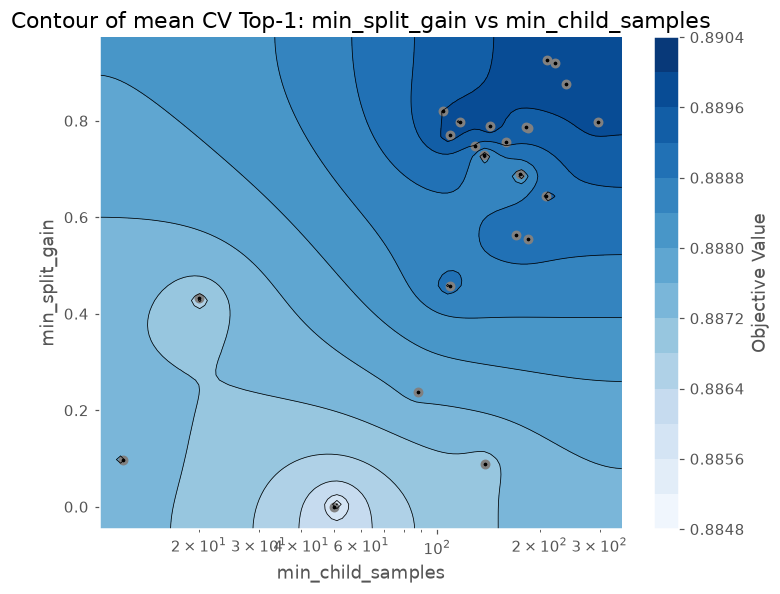

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6160\798338064.py:5: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig = np.atleast_1d(axes)[0].figure; fig.set_size_inches(10, 4); fig.tight_layout()


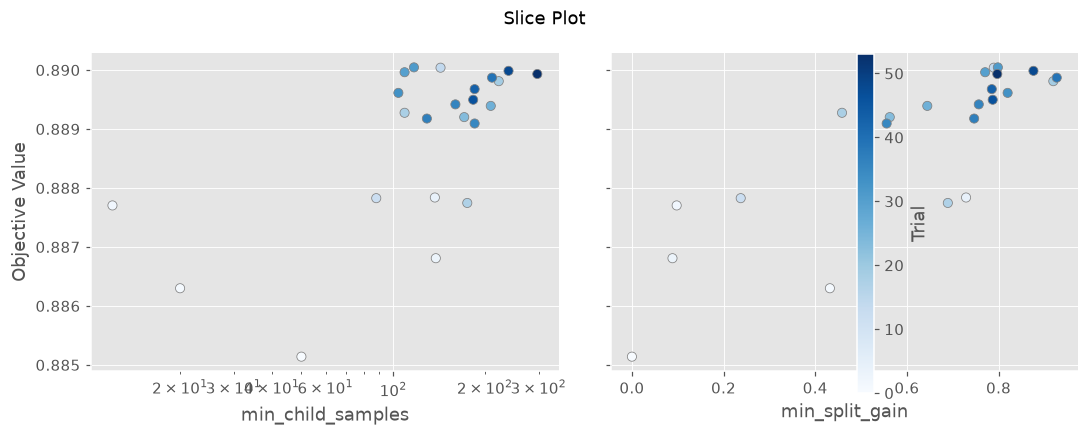

In [9]:
ax = ovm.plot_contour(study, params=top2)
ax.figure.set_size_inches(7, 5.5); ax.set_title(f"Contour of mean CV Top-1: {top2[0]} vs {top2[1]}")
ax.figure.tight_layout(); ax.figure.savefig(FIG / "contour_top2.png"); plt.show()
axes = ovm.plot_slice(study, params=top2)
fig = np.atleast_1d(axes)[0].figure; fig.set_size_inches(10, 4); fig.tight_layout()
fig.savefig(FIG / "slice_top2.png"); plt.show()

## 4. Refit the best configuration on all usable train trips, then score student_test once

In [10]:
spec = TU.lgbm_spec(best.params)
model, fit_s, _ = T.fit_model(spec, train[T.training_mask(train)])
p, pred_s = T.predict(model, test)
m = T.evaluate(test, test_fx, p, arcs)
path = MODELS / "LightGBM_tuned.joblib"
joblib.dump(model, path, compress=3)

# timing check: re-time the untuned model now, on the same machine state, for a fair inference comparison
untuned = joblib.load(MODELS / "LightGBM.joblib")
_, pred_untuned_now = T.predict(untuned, test)
tuned = {"fit_s": fit_s, "infer_ms_per_1k_fixes": 1e6 * pred_s / len(test_fx), "model_file_mb": path.stat().st_size / 1e6,
         **{k: v for k, v in m.items() if not k.endswith("_cm")}}
(OUT / "tuned_student_test_cm.json").write_text(json.dumps({"all": m["all_cm"], "reliable": m["reliable_cm"]}), encoding="utf-8")
print(f"tuned: student_test Top-1 {m['all_top1']:.4f}, macro F1 {m['all_macro_f1']:.4f}, log loss {m['all_logloss']:.4f}, "
      f"fit {fit_s:.0f}s, {tuned['infer_ms_per_1k_fixes']:.0f} ms / 1k fixes")
print(f"untuned re-timed now: {1e6 * pred_untuned_now / len(test_fx):.0f} ms / 1k fixes")

tuned: student_test Top-1 0.8961, macro F1 0.9384, log loss 0.0577, fit 16s, 50 ms / 1k fixes
untuned re-timed now: 40 ms / 1k fixes


## 5. Tuned vs untuned (Random Forest as a reference)
The untuned LightGBM and Random Forest numbers are read unchanged from notebook 04 (`outputs/models/`). The tuned CV
numbers are those of the best trial, on the same folds.

In [11]:
mc = pd.read_csv(ROOT / "outputs" / "models" / "model_comparison.csv").set_index("model")
pf = nb04.groupby("model")
def from_nb04(name):
    g = pf.get_group(name); r = mc.loc[name]
    return {"CV macro F1": g.all_macro_f1.mean(), "CV macro F1 std": g.all_macro_f1.std(),
            "CV Top-1": g.all_top1.mean(), "CV Top-1 std": g.all_top1.std(), "CV log loss": g.all_logloss.mean(),
            "ST Top-1": r["ST Top-1 (all)"], "ST Top-1 (reliable)": r["ST Top-1 (reliable)"],
            "ST macro F1": r["ST macro F1 (all)"], "ST log loss": r["ST log loss (all)"],
            "ST route continuity": r["ST route continuity"], "train time (s)": r["train time (s)"],
            "inference ms / 1k fixes": r["inference ms / 1k fixes"], "model file (MB)": r["model file (MB)"]}
ua = best.user_attrs
comp = pd.DataFrame({
    "LightGBM untuned": from_nb04("LightGBM"),
    "LightGBM tuned": {"CV macro F1": ua["cv_all_macro_f1_mean"], "CV macro F1 std": ua["cv_all_macro_f1_std"],
                       "CV Top-1": ua["cv_all_top1_mean"], "CV Top-1 std": ua["cv_all_top1_std"],
                       "CV log loss": ua["cv_all_logloss_mean"], "ST Top-1": tuned["all_top1"],
                       "ST Top-1 (reliable)": tuned["reliable_top1"], "ST macro F1": tuned["all_macro_f1"],
                       "ST log loss": tuned["all_logloss"], "ST route continuity": tuned["route_continuity"],
                       "train time (s)": tuned["fit_s"], "inference ms / 1k fixes": tuned["infer_ms_per_1k_fixes"],
                       "model file (MB)": tuned["model_file_mb"]},
    "RandomForest (reference)": from_nb04("RandomForest"),
}).T
comp.to_csv(OUT / "tuned_vs_untuned.csv")
comp.round(4).T

,LightGBM untuned,LightGBM tuned,RandomForest (reference)
CV macro F1,0.9328,0.9362,0.9342
CV macro F1 std,0.0212,0.0207,0.0203
CV Top-1,0.8851,0.8900,0.8871
CV Top-1 std,0.0379,0.0384,0.0372
CV log loss,0.0703,0.0681,0.0695
ST Top-1,0.8943,0.8961,0.9001
ST Top-1 (reliable),0.8955,0.8972,0.9012
ST macro F1,0.9352,0.9384,0.9395
ST log loss,0.0574,0.0577,0.0589
ST route continuity,0.9595,0.9597,0.9556


In [12]:
# per-fold: is the CV gain consistent, or one lucky fold?
paired = pd.DataFrame({"untuned": nb04_lgb.all_top1.to_numpy(),
                       "tuned": [ua[f"fold{k}_all_top1"] for k in range(T.N_FOLDS)],
                       "RandomForest": nb04[nb04.model == "RandomForest"].sort_values("fold").all_top1.to_numpy()},
                      index=[f"fold {k}" for k in range(T.N_FOLDS)])
paired["tuned - untuned (pp)"] = 100 * (paired.tuned - paired.untuned)
paired["tuned - RF (pp)"] = 100 * (paired.tuned - paired.RandomForest)
paired.to_csv(OUT / "per_fold_top1.csv")
paired.round(4)

,untuned,tuned,RandomForest,tuned - untuned (pp),tuned - RF (pp)
fold 0,0.8474,0.8515,0.8486,0.4139,0.2920
fold 1,0.9178,0.9274,0.9190,0.9603,0.8443
fold 2,0.8782,0.8846,0.8832,0.6357,0.1369
fold 3,0.9307,0.9319,0.9309,0.1167,0.0979
fold 4,0.8515,0.8548,0.8537,0.3258,0.1129


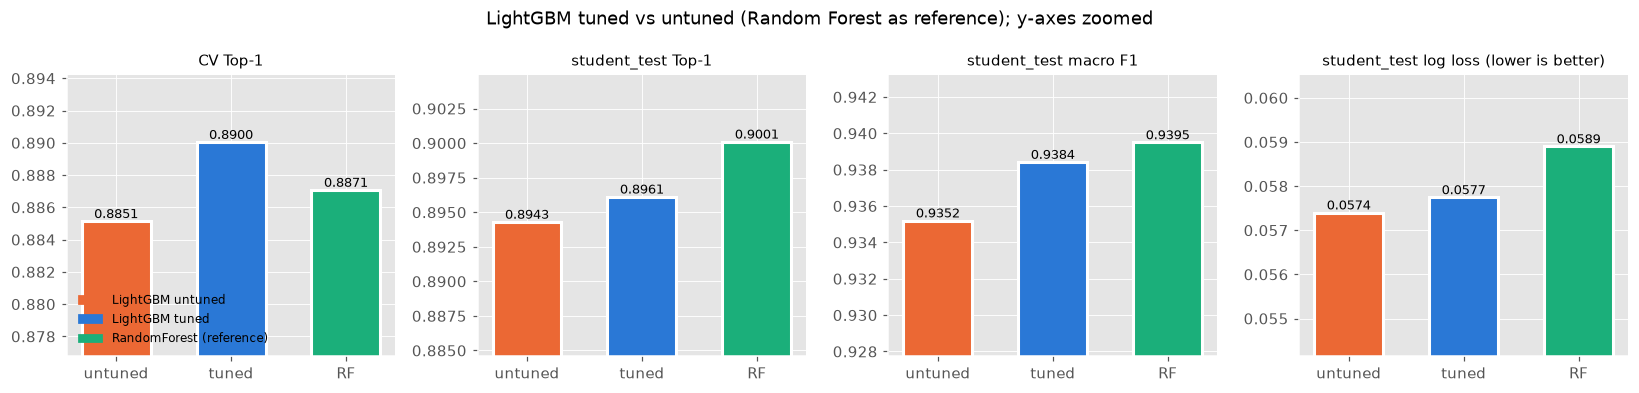

In [13]:
show = [("CV Top-1", "CV Top-1"), ("ST Top-1", "student_test Top-1"), ("ST macro F1", "student_test macro F1"),
        ("ST log loss", "student_test log loss (lower is better)")]
names = list(comp.index); colors = ["#eb6834", "#2a78d6", "#1baf7a"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (col, title) in zip(axes, show):
    v = comp[col].astype(float).values
    ax.bar(range(3), v, 0.6, color=colors, edgecolor="white", linewidth=2)
    for i, x in enumerate(v):
        ax.text(i, x, f"{x:.4f}", ha="center", va="bottom", fontsize=8.5)
    pad = (v.max() - v.min()) * 1.5 + 1e-3
    ax.set_ylim(v.min() - pad, v.max() + pad / 2); ax.set_xticks(range(3), ["untuned", "tuned", "RF"])
    ax.set_title(title, fontsize=10)
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colors], labels=names, frameon=False,
               fontsize=8, loc="lower left")
fig.suptitle("LightGBM tuned vs untuned (Random Forest as reference); y-axes zoomed")
fig.tight_layout(); fig.savefig(FIG / "tuned_vs_untuned.png"); plt.show()

## 6. Write `TUNING_REPORT.md`

In [14]:
c = comp.astype(float)
d_cv = 100 * (c.loc["LightGBM tuned", "CV Top-1"] - c.loc["LightGBM untuned", "CV Top-1"])
d_st = 100 * (c.loc["LightGBM tuned", "ST Top-1"] - c.loc["LightGBM untuned", "ST Top-1"])
folds_up = int((paired["tuned - untuned (pp)"] > 0).sum())
bp = pd.Series(best.params).to_frame("best value")
bp["untuned value"] = pd.Series(TU.BASELINE)
L = ["# PathSnap: Bayesian Hyperparameter Optimisation of LightGBM", "",
     "Auto-generated by `notebooks/05_bayesian_tuning.ipynb` (seed 42). Every number comes from that run.", "",
     "## 1. Which hyperparameters were searched?", "",
     "learning_rate, n_estimators, num_leaves, max_depth, min_child_samples, subsample (with subsample_freq=1), "
     "colsample_bytree, reg_alpha, reg_lambda, min_split_gain.", "",
     "## 2. What ranges / distributions?", "", pd.DataFrame(TU.SEARCH_SPACE).T.fillna("").to_markdown(), "",
     "## 3. What objective was optimised?", "",
     "Maximise the **mean CV observation-level Top-1 accuracy** (all labelled fixes of non-excluded trips) over the same "
     "5 GroupKFold folds (by trip, seed 42) as notebook 04. Top-1 is the real task: for each GPS fix, pick the right road. "
     "Macro F1 and log loss score single candidate rows at a 0.5 threshold, which the pipeline never uses, so they "
     "were logged for every trial but not optimised. Sampler: TPE (seed 42). Pruner: MedianPruner (from the first fold, after "
     f"{TU.PRUNER_STARTUP_TRIALS} finished trials). student_test was not used during the search.", "",
     "## 4. How many trials?", "",
     f"{summary['trials_total']} trials in {summary['wall_clock_min']} min: {summary['complete']} completed, "
     f"{summary['pruned']} pruned, {summary['failed']} failed (limit: {TU.N_TRIALS} trials or {TU.TIMEOUT_S // 60} min). "
     "Trial 0 was the untuned configuration.", "",
     "## 5. Best hyperparameters", "", f"Best trial: #{best.number}, mean CV Top-1 = {best.value:.4f}.", "",
     bp.to_markdown(), "",
     "## 6. Did the tuned model beat the untuned one?", "",
     f"CV Top-1 changed by {d_cv:+.2f} percentage points (higher in {folds_up} of 5 folds); student_test Top-1 changed by "
     f"{d_st:+.2f} pp. Full comparison (untuned LightGBM and Random Forest from notebook 04):", "",
     comp.round(4).to_markdown(), "",
     "Per fold, CV Top-1:", "", paired.round(4).to_markdown(), "",
     "## Figures", "", *[f"![{p.stem}](figures/{p.name})" for p in sorted(FIG.glob("*.png"))], ""]
(OUT / "TUNING_REPORT.md").write_text("\n".join(L), encoding="utf-8")
print("wrote", OUT / "TUNING_REPORT.md")

wrote C:\College\sem-v\ml\ml_hackathon\PATHSNAP\outputs\tuning\TUNING_REPORT.md


## 7. Reading the results (written after this run)

* **Tuning helped, but only a little.** CV Top-1 went from 0.8851 to 0.8900 (+0.49 pp), higher in all 5 folds
  (+0.12 to +0.96 pp). That is consistent, so it is not one lucky fold. On student_test, Top-1 went from 0.8943 to 0.8961
  (+0.18 pp) and macro F1 from 0.9352 to 0.9384. Student_test log loss stayed about the same (0.0574 → 0.0577).
* **Random Forest:** tuned LightGBM now beats it in cross-validation (0.8900 vs 0.8871, ahead in all 5 folds), but RF
  is still higher on student_test Top-1 (0.9001 vs 0.8961). These 10 trips are only one sample, and the gaps are a few
  tenths of a percentage point.
* **What the search learned:** the best region is a *simpler, more regularised* model than the untuned one. It has fewer
  leaves (17–34 instead of 63), large `min_child_samples` (100–300), a high `min_split_gain` (~0.6–0.9), and strong row
  and column subsampling. fANOVA attributes 55 % of the score variance to `min_split_gain`. The untuned model was
  slightly overfitting the training trips.
* **Plateau:** the 10 best completed trials are within 0.0005 CV Top-1 of each other, so the exact best values are not
  important. Trial 31 is reported because it is the first one that reached that level.
* **Boundary values:** every top trial picked `max_depth = 12`, but with only ~23 leaves a depth of 12 never limits
  the tree, so this is effectively "no depth limit". The best `min_split_gain` (0.80) is near the top of its 0–1
  range. A wider range might give a little more, but the plateau suggests the gain would be small.
* **Pruning:** 37 of 60 trials were stopped early (33 of them after one fold), so the search took 42 min instead of
  hours. Pruned trials do not have a comparable score: `trials.csv` keeps their running mean separately and leaves
  `value` empty.
* **Training and inference cost:** the tuned model trains in 16 s (untuned 29 s in notebook 04) and its file is 0.7 MB
  (vs 1.3 MB). The inference figure of 86.7 ms / 1k fixes for the untuned model comes from notebook 04 under a different
  machine load. Re-timed in the same session, untuned took **40 ms** and tuned **50 ms** per 1,000 fixes. The tuned
  model has more trees (600 vs 400), so it is slightly *slower* at prediction, though still fast.
* **Sanity check:** trial 0 (the untuned configuration, re-run inside the search) reproduced notebook 04's per-fold Top-1
  exactly, so the folds, rows and metrics are identical between the two notebooks.